# [Lab Session 4](deconvolution.ipynb)

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from skimage.restoration import wiener
from scipy.signal import convolve2d as conv
from scipy.stats import multivariate_normal as multi_normal

np.random.seed(0)

Load the image.

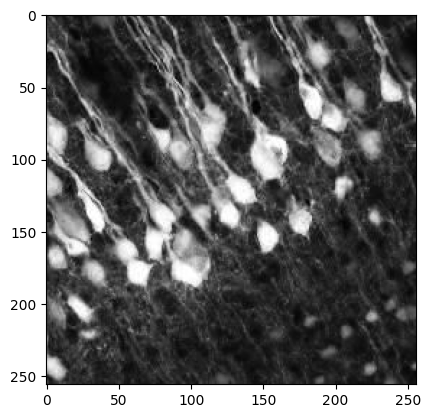

In [7]:
img = plt.imread('data/cells.png')[128:384, 128:384]
plt.imshow(img, 'gray')
plt.show()

**[Task 1.]()** Apply the following PSF to the image and then display it.

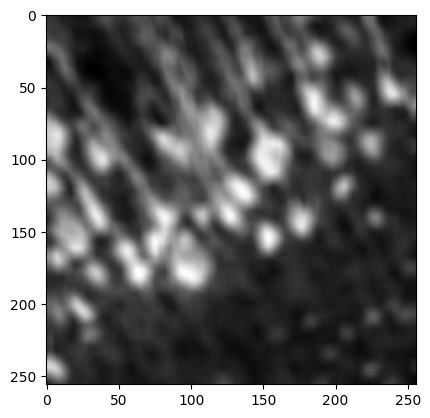

In [39]:
psf_size = 10
psf = np.ones((psf_size, psf_size)) / psf_size ** 2 #array aus einzen 111111111 hihihi

img_psf = conv(img, psf, mode='same', boundary='symm')

plt.figure()
plt.imshow(img_psf, "gray")
plt.show()

**[Task 2.]()** Have a look at the Gaussian PSF which is not uniformly distributed. Apply it to the image.

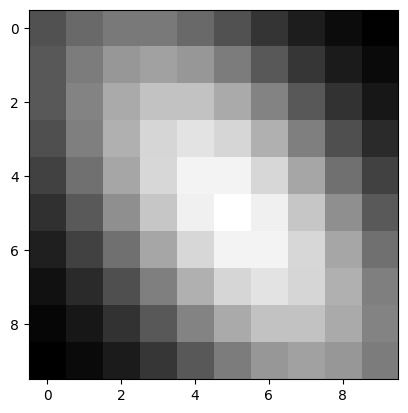

In [40]:
def create_psf(size):
    factor = size * 1.8
    x, y = np.mgrid[0:size:1, 0:size:1]
    pos = np.empty(x.shape + (2,))
    pos[:, :, 0] = x
    pos[:, :, 1] = y
    rv = multi_normal([int(size / 2), (int(size / 2))], [[factor * 1., factor * 1.2], [factor * .5, factor * .7]])
    return rv.pdf(pos)

plt.imshow(create_psf(psf_size), 'gray')
plt.show()

Apply the second psf to the image:

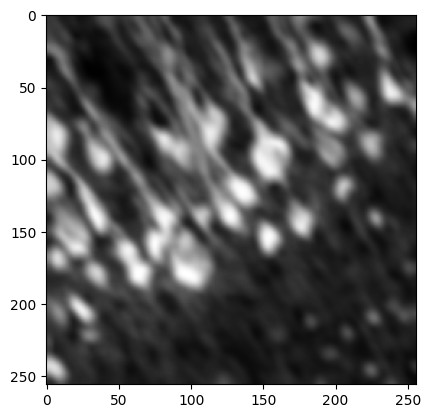

In [41]:
psf_gaussian = create_psf(psf_size)
psf_gaussian /= np.sum(psf_gaussian)
#anwenden mit der funktion conv
img_psf_gaussian = conv(img, psf_gaussian, mode='same', boundary='symm')

plt.imshow(img_psf_gaussian, cmap='gray')
plt.show()

**[Task 3.]()** Implement a reusable function that performs the Richardson-Lucy deconvolution.

In [42]:
def richardson_lucy_deconvolution(image, psf, n_iterations):
    img_deconv = np.full(image.shape, 0.5) #img_deconv ist ein Bild (ein NumPy-Array), keine Funktion
    psf_flipped = np.flip(psf)
    
    for _ in range(n_iterations):
        img_deconv = img_deconv * (conv(image / conv(img_deconv, psf, mode='same', boundary='symm'), psf_flipped, mode='same', boundary='symm'))

    img_deconv = img_deconv.clip(0,1)
    return img_deconv

**[Task 4.]()** Apply the Richardson-Lucy deconvolution to the blurred image.

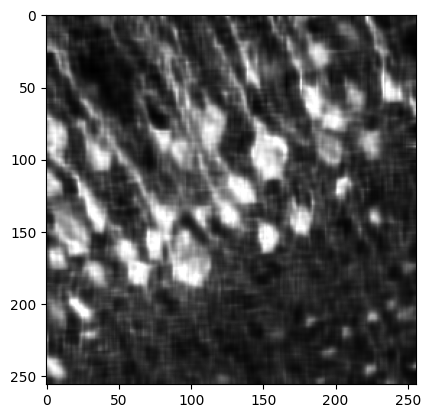

In [43]:
#die RL auf mein blurred image anwenden udn sie damit "deconvoluten"
img_RL = richardson_lucy_deconvolution(img_psf, psf, 100) # je höher n_iterations, desto besser wird das bild, allerdings macht es irgendwann so seltsame Caros
plt.imshow(img_RL, cmap="gray")
plt.show()

# conv(bild, psf, ...): Das Werkzeug für den Hinweg (Convolution / Faltung). Es nimmt ein scharfes Bild und verschmiert es mithilfe der PSF.
# richardson_lucy_deconvolution(bild, psf, anzahl): Das Werkzeug für den Rückweg (Deconvolution / Entfaltung). Es nimmt ein unscharfes Bild und rechnet es mithilfe derselben PSF wieder scharf.

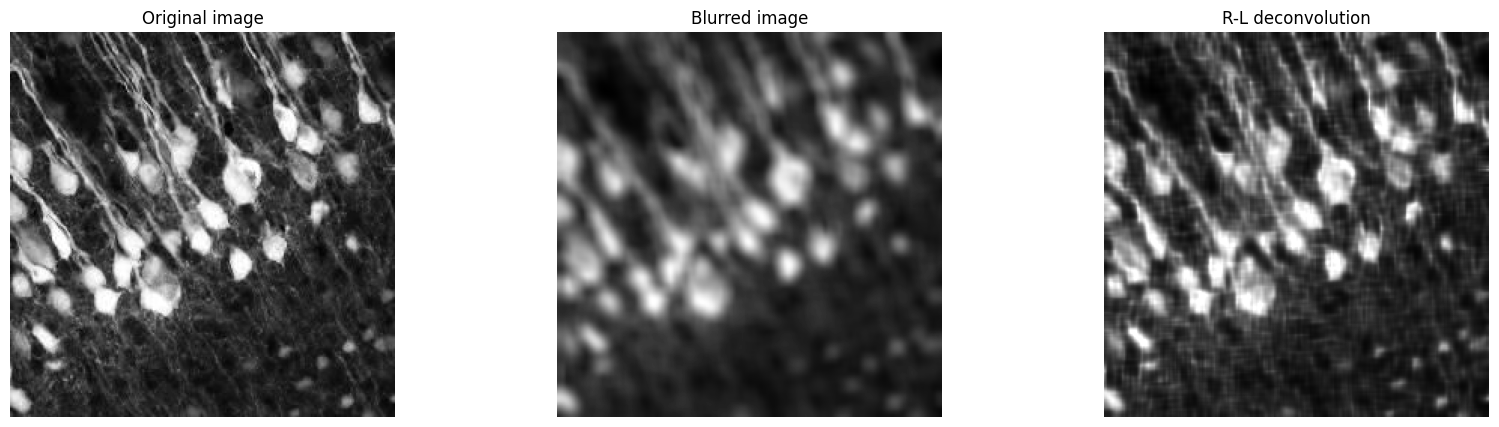

In [44]:
plt.figure(figsize=(20,5))

plt.subplot(1, 3, 1)
plt.axis('off')
plt.imshow(img, 'gray')
plt.title('Original image')

plt.subplot(1, 3, 2)
plt.axis('off')
plt.imshow(img_psf, 'gray')
plt.title('Blurred image')

plt.subplot(1, 3, 3)
plt.axis('off')
plt.imshow(img_RL, 'gray')
plt.title('R-L deconvolution')
plt.show()

**[Task 5.]()** Add noise to the image, use the R-L deconvolution again.

In [ ]:
noise = (np.random.normal(loc=0,size=img.shape))
reduce_factor = 5 #je kleiner, desto schärfer wird das blurred bild
noise = noise / reduce_factor

#add noise to img_psf
img_psf_white_noise = img_psf + noise #einfache addition geht, weio beides genau glecih froße arrays sind
img_psf_white_noise = img_psf_white_noise.clip(0,1)

#nochmal RL machen
img_white_noise_RL = richardson_lucy_deconvolution(img_psf_white_noise, psf, 10)

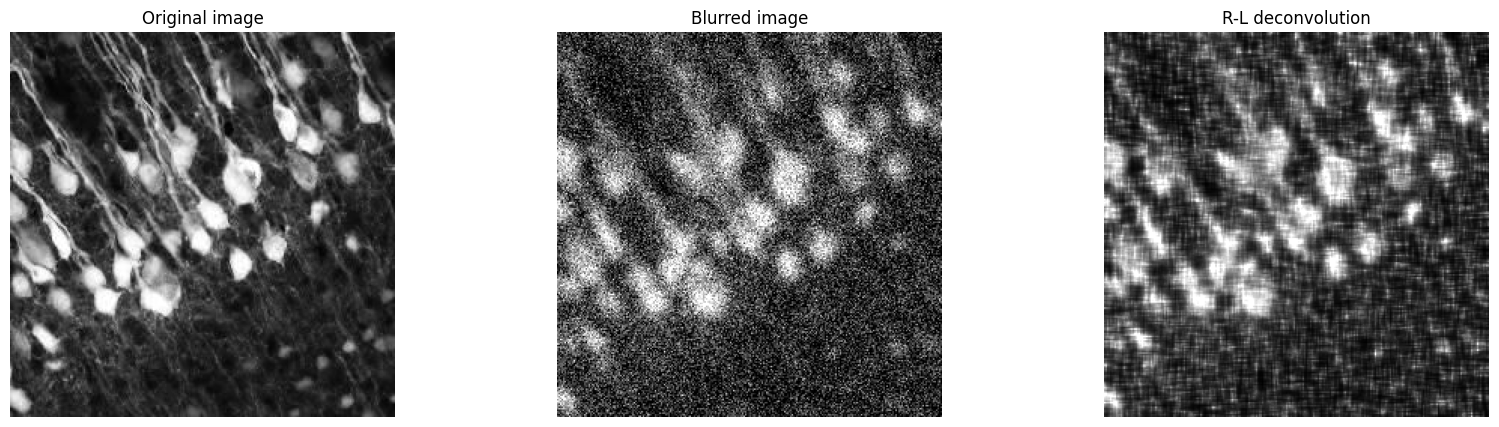

In [55]:
plt.figure(figsize=(20,5))

plt.subplot(1, 3, 1)
plt.axis('off')
plt.imshow(img, 'gray')
plt.title('Original image')

plt.subplot(1, 3, 2)
plt.axis('off')
plt.imshow(img_psf_white_noise, 'gray')
plt.title('Blurred image')

plt.subplot(1, 3, 3)
plt.axis('off')
plt.imshow(img_white_noise_RL, 'gray')
plt.title('R-L deconvolution')
plt.show()

**[Task 6.]()** Compare your R-L implementation to a wiener deconvolution.

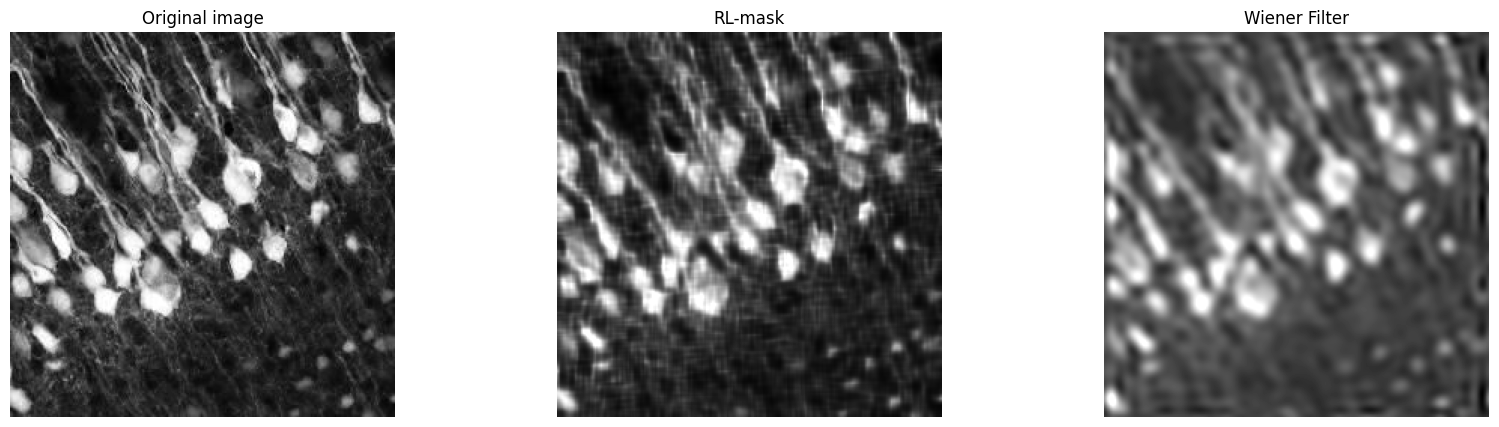

In [64]:
img_wiener = wiener(img_psf, psf, balance=0.5, clip=True)

plt.figure(figsize=(20,5))

plt.subplot(1,3,1)
plt.axis('off')
plt.imshow(img, 'gray')
plt.title('Original image')


plt.subplot(1,3,2)
plt.axis("off")
plt.imshow(img_RL, "gray")
plt.title("RL-mask")

plt.subplot(1,3,3)
plt.axis("off")
plt.imshow(img_wiener, "gray")
plt.title("Wiener Filter")
plt.show()

**[Task 7.]()** Repeat Tasks 4–6 using a smaller value for the size of the PSF.

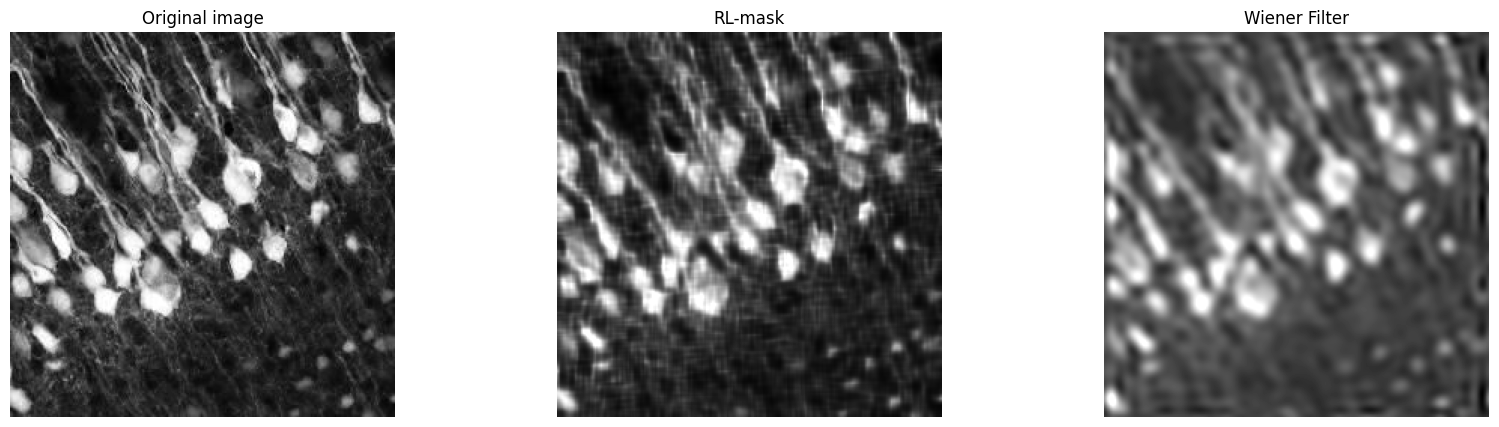

In [66]:
psf_size = 5

img_wiener = wiener(img_psf, psf, balance=0.5, clip=True)

plt.figure(figsize=(20,5))

plt.subplot(1,3,1)
plt.axis('off')
plt.imshow(img, 'gray')
plt.title('Original image')


plt.subplot(1,3,2)
plt.axis("off")
plt.imshow(img_RL, "gray")
plt.title("RL-mask")

plt.subplot(1,3,3)
plt.axis("off")
plt.imshow(img_wiener, "gray")
plt.title("Wiener Filter")
plt.show()

**[Task 8.]()** Use a wrong PSF to restore the image

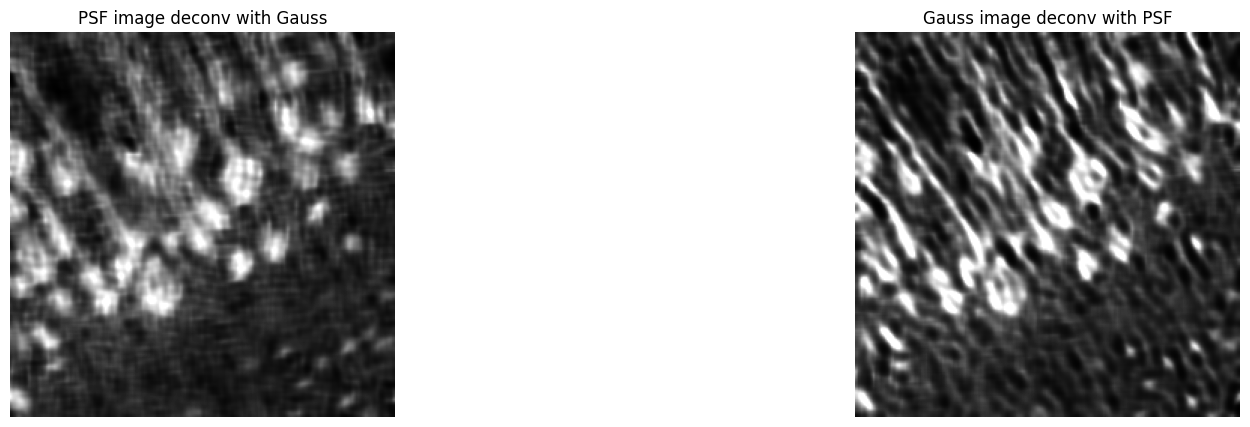

In [68]:
img_RL_wrong_1 = richardson_lucy_deconvolution(img_psf, psf_gaussian, 100)
img_RL_wrong_2 = richardson_lucy_deconvolution(img_psf_gaussian, psf, 100)

plt.figure(figsize=(20,5))

plt.subplot(1,2,1)
plt.axis('off')
plt.imshow(img_RL_wrong_1, 'gray')
plt.title('PSF image deconv with Gauss')


plt.subplot(1,2,2)
plt.axis("off")
plt.imshow(img_RL_wrong_2, "gray")
plt.title("Gauss image deconv with PSF")

plt.show()
